# Data Understanding and Preprocessing

## Setup

In [17]:
import json
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
import albumentations as A
from sklearn.model_selection import GroupKFold
from tqdm import tqdm

In [18]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = Path("data")
OUT_DIR = Path("data_prepared")
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
IMG_SIZE = 1280
IGNORE_COLOR = (114, 114, 114)

NAVY, LIGHT, MID = "#1B2A4A", "#8EC5E8", "#4A7FB5"
SPLIT_COLORS = {"train": NAVY, "val": LIGHT, "test": MID}
CLASS_COLORS = sns.color_palette("tab10", len(CLASSES))
sns.set_theme(style="whitegrid", palette=[NAVY, LIGHT, MID])

## Load annotations

We read the annotation files of train and val. Each annotation is one box: which frame it is on, its class and its position.

Ignored regions are areas the annotators didn't label (for example a far crowd). In the file they are marked with iscrowd = 1 and are repeated once for every class,
so we keep only one copy and store them separately from normal objects. The original VisDrone class "others" is already removed by the organisers, so there are no non-target classes left.

Image ids start from 1 again in every split, so we give every frame a unique id.

In [19]:
def load_split(split):
    coco = json.loads((DATA_DIR / split / "annotations_coco.json").read_text())
    images = pd.DataFrame(coco["images"]).rename(columns={"id": "image_id"}).assign(split=split)
    anns = pd.DataFrame(coco["annotations"]).merge(images[["image_id", "video", "frame_id", "width", "height"]], on="image_id")
    anns[["x", "y", "w", "h"]] = pd.DataFrame(anns["bbox"].tolist(), index=anns.index)
    anns["ignore"] = anns["ignore"].fillna(0).astype(int)
    images["uid"] = split + "_" + images["image_id"].astype(str)
    anns["uid"] = split + "_" + anns["image_id"].astype(str)
    anns["split"] = split
    return images, anns.drop(columns=["bbox", "segmentation"], errors="ignore")


splits = [load_split(s) for s in ["train", "val"]]
images = pd.concat([s[0] for s in splits], ignore_index=True)
anns = pd.concat([s[1] for s in splits], ignore_index=True)
test_images = pd.read_csv(DATA_DIR / "test_images.csv").rename(columns={"clip": "video", "frame": "frame_id"}).assign(split="test")

objects = anns[anns["ignore"] == 0].copy()
objects["cls"] = objects["category_id"] - 1
objects["class"] = objects["cls"].map(dict(enumerate(CLASSES)))
objects["size"] = np.sqrt(objects["w"] * objects["h"])
objects["size_input"] = objects["size"] * IMG_SIZE / np.maximum(objects["width"], objects["height"])
objects["aspect"] = objects["w"] / objects["h"]
ignored = anns[anns["ignore"] == 1].drop_duplicates(["uid", "x", "y", "w", "h"])

In [20]:
images.groupby("split").agg(
    sequences=("video", "nunique"),
    frames=("uid", "size"),
).join(objects.groupby("split").size().rename("objects")).join(ignored.groupby("split").size().rename("ignored_regions"))

,sequences,frames,objects,ignored_regions
split,,,,
train,56,24201,1105516,63843
val,7,2846,114132,3995


## Frame resolution: train, val and test

Frames have different sizes in different videos. We also look at the test set, because the model will be used on test frames.
For test we only use the sizes listed in test_images.csv, not the test images themselves.

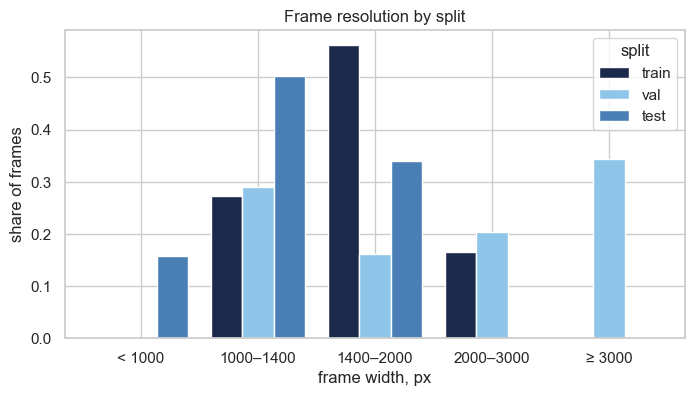

split,train,val,test
resolution,,,
< 1000,0.000,0.000,0.157
1000–1400,0.273,0.291,0.502
1400–2000,0.563,0.161,0.340
2000–3000,0.164,0.204,0.000
≥ 3000,0.000,0.344,0.000


In [21]:
res_frames = pd.concat([images[["split", "width"]], test_images[["split", "width"]]], ignore_index=True)
res_frames["resolution"] = pd.cut(res_frames["width"], [0, 1000, 1400, 2000, 3000, 4000], labels=["< 1000", "1000–1400", "1400–2000", "2000–3000", "≥ 3000"])
res_share = pd.crosstab(res_frames["resolution"], res_frames["split"], normalize="columns")[["train", "val", "test"]]

ax = res_share.plot.bar(figsize=(8, 4), color=SPLIT_COLORS, rot=0, width=0.8)
ax.set(xlabel="frame width, px", ylabel="share of frames", title="Frame resolution by split")
plt.show()
res_share.round(3)

This plot shows for each split (train, val, test), what share of its frames has each frame width.

No train frame is narrower than 1000 px, but 15.7 % of test frames are. In val 34.4 % of frames are 3000 px or wider, while no test frame is wider than 2000 px. 

## Class distribution

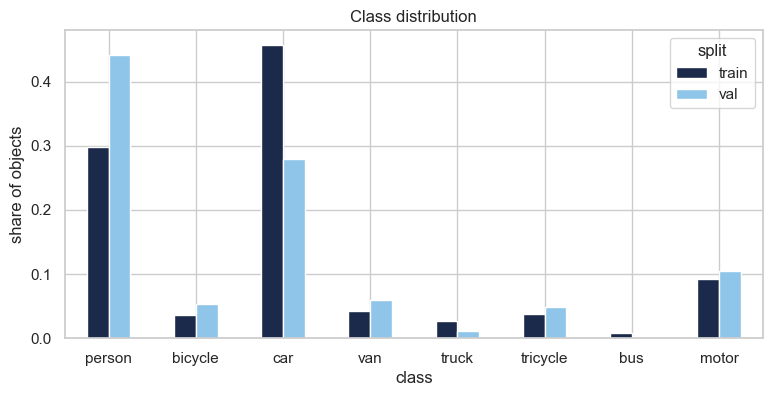

split,train,val,train_share
class,,,
person,328701,50312,0.297
bicycle,40255,6022,0.036
car,505301,31821,0.457
van,46940,6842,0.042
truck,30498,1359,0.028
tricycle,41349,5487,0.037
bus,9653,264,0.009
motor,102819,12025,0.093


In [22]:
class_counts = objects.groupby(["split", "class"]).size().unstack(0).loc[CLASSES]
class_share = class_counts / class_counts.sum()

fig, ax = plt.subplots(figsize=(9, 4))
class_share.plot.bar(ax=ax, color=SPLIT_COLORS, rot=0)
ax.set(ylabel="share of objects", title="Class distribution")
plt.show()
class_counts.assign(train_share=class_share["train"].round(3))

This plot shows the share of each class among all objects, separately for train and val.

Cars and people are three quarters of all train objects, while buses are under 1 % and trucks about 3 %. In val there are more people than cars, so val has a different class mix than train.

Now the same, but for every video separately. Videos are sorted by their main class, so similar scenes are next to each other.

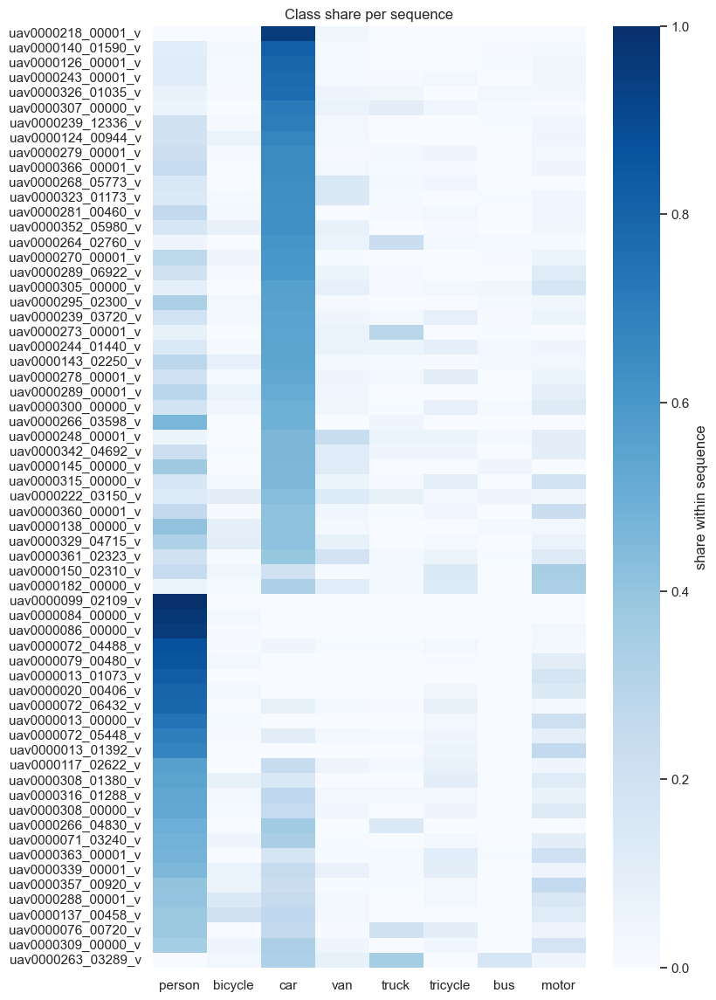

In [23]:
seq_class = pd.crosstab(objects["video"], objects["class"], normalize="index")[CLASSES]
seq_order = pd.DataFrame({"main": seq_class.idxmax(axis=1), "share": seq_class.max(axis=1)}).sort_values(["main", "share"], ascending=[True, False]).index

fig, ax = plt.subplots(figsize=(8, 14))
sns.heatmap(seq_class.loc[seq_order], cmap="Blues", ax=ax, cbar_kws={"label": "share within sequence"})
ax.set(title="Class share per sequence", xlabel="", ylabel="")
plt.show()

Here each row is one video, each column a class. The darker the cell, the larger the share of that class in the video. Almost every video is mostly cars or mostly people. 

## Object sizes

To describe the size of a box with one number we use the square root of width × height: the side of a square with the same area.
For example, a 20 × 80 box and a 40 × 40 box both have size 40.
COCO, the standard we use for evaluation, calls an object small if its size is below 32 px, medium if it is between 32 and 96 px, and large otherwise.

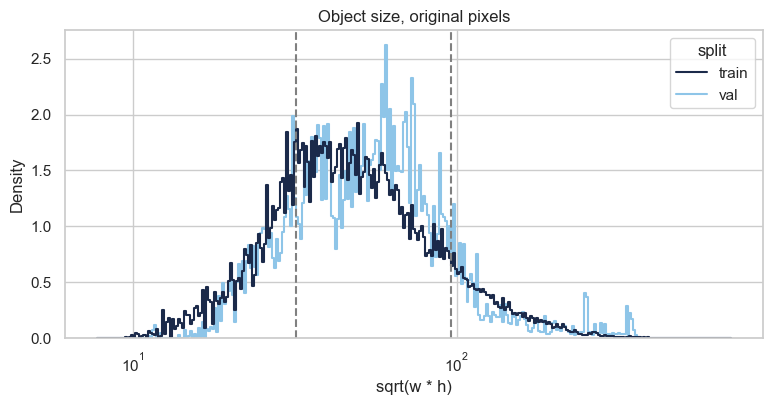

coco_bucket,small,medium,large
split,,,
train,0.249,0.635,0.116
val,0.192,0.695,0.113


In [24]:
objects["coco_bucket"] = pd.cut(objects["w"] * objects["h"], [0, 32 ** 2, 96 ** 2, np.inf], labels=["small", "medium", "large"])

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(objects, x="size", hue="split", log_scale=True, stat="density", common_norm=False, element="step", fill=False, palette=SPLIT_COLORS, ax=ax)
for limit in [32, 96]:
    ax.axvline(limit, color="grey", ls="--")
ax.set(title="Object size, original pixels", xlabel="sqrt(w * h)")
plt.show()
pd.crosstab(objects["split"], objects["coco_bucket"], normalize="index").round(3)

This plot shows how often each object size appears (x-axis is logarithmic). The dashed lines are the COCO borders between small, medium and large objects.

In original pixels 25 % of train objects are small, 64 % medium and 12 % large, and val is similar.

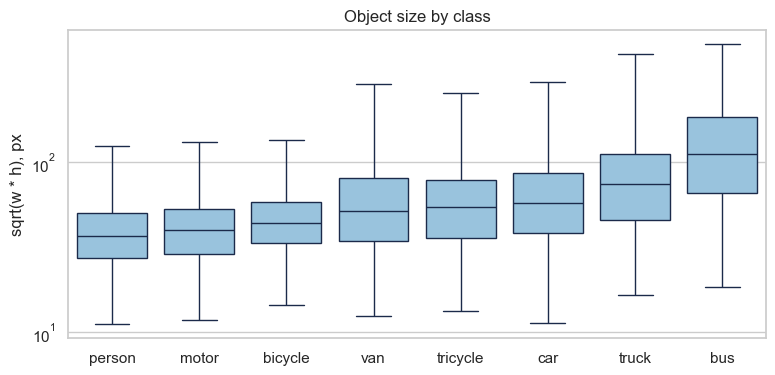

In [25]:
size_order = objects.groupby("class")["size"].median().sort_values().index

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(objects, x="class", y="size", order=size_order, color=LIGHT, linecolor=NAVY, log_scale=True, showfliers=False, ax=ax)
ax.set(title="Object size by class", xlabel="", ylabel="sqrt(w * h), px")
plt.show()

This plot shows for each class, the box shows where the middle half of object sizes lies, the line inside is the median, the whiskers show the usual range.

People, motors and bicycles are the smallest (median about 37–44 px), buses the biggest (about 110 px). The boxes of most classes overlap a lot, so size alone doesn't separate classes.

Before training, every frame is made smaller so that its longer side equals the input size. Objects shrink with the frame.
The table shows what share of objects would become smaller than 8, 16 or 32 px for different input sizes.

In [26]:
scale_rows = []
for imgsz in [640, 960, 1280, 1536]:
    scaled = objects["size"] * imgsz / np.maximum(objects["width"], objects["height"])
    scale_rows.append({"imgsz": imgsz, "median_px": scaled.median(), "< 8 px": (scaled < 8).mean(), "< 16 px": (scaled < 16).mean(), "< 32 px": (scaled < 32).mean()})
res_table = pd.DataFrame(scale_rows).set_index("imgsz")
res_table.round(3)

,median_px,< 8 px,< 16 px,< 32 px
imgsz,,,,
640,15.286,0.097,0.536,0.892
960,22.929,0.018,0.235,0.732
1280,30.572,0.006,0.097,0.536
1536,36.686,0.002,0.048,0.394


## Perspective: object size vs position in the frame

Most videos are filmed at an angle, not straight down, so objects far away (top of the frame) look smaller than objects close to the camera (bottom of the frame).
We check this by measuring the typical object size at different heights in the frame.
This matters for augmentation: a horizontal flip keeps far objects at the top, so the frame still looks real, while a vertical flip would put the small far objects at the bottom.

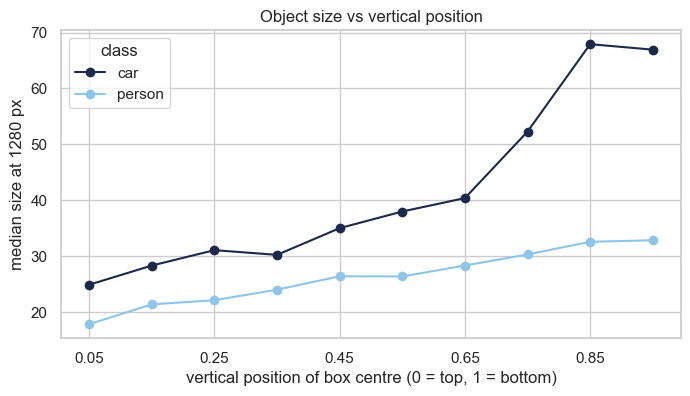

In [27]:
objects["y_rel"] = (objects["y"] + objects["h"] / 2) / objects["height"]
objects["y_bin"] = pd.cut(objects["y_rel"], np.linspace(0, 1, 11), labels=np.round(np.linspace(0.05, 0.95, 10), 2))
perspective = objects[objects["class"].isin(["person", "car"])].groupby(["y_bin", "class"], observed=True)["size_input"].median().unstack()

ax = perspective.plot(marker="o", color=[NAVY, LIGHT], figsize=(8, 4))
ax.set(xlabel="vertical position of box centre (0 = top, 1 = bottom)", ylabel=f"median size at {IMG_SIZE} px", title="Object size vs vertical position")
plt.show()

The frame is split into 10 horizontal stripes from top (0) to bottom (1). This plot shows for each stripe, the median size of cars and people whose centre is in it.

Cars at the top of the frame are about 25 px and at the bottom about 67 px, people grow from 18 to 33 px. So far objects are 2–3 times smaller than close ones.

## Confusable classes

Some classes look alike from above: car and van, bicycle and motor, van and truck, truck and bus.
We compare the box sizes of each pair. Sizes are recalculated as if every frame were resized to the input size (1280 px), so frames of different resolution can be compared.

In [28]:
PAIRS = [("bicycle", "motor"), ("car", "van"), ("van", "truck"), ("truck", "bus")]

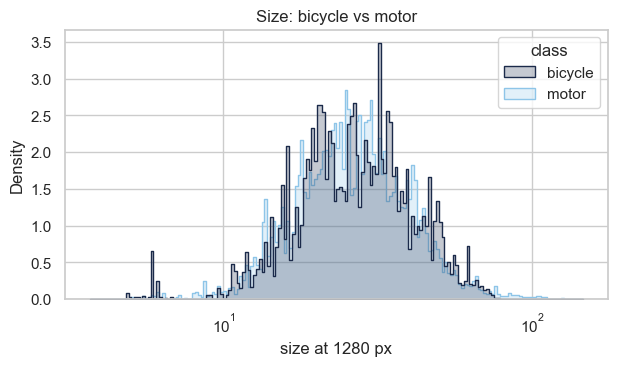

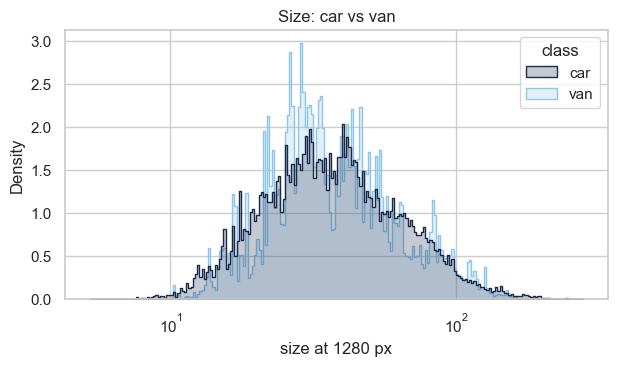

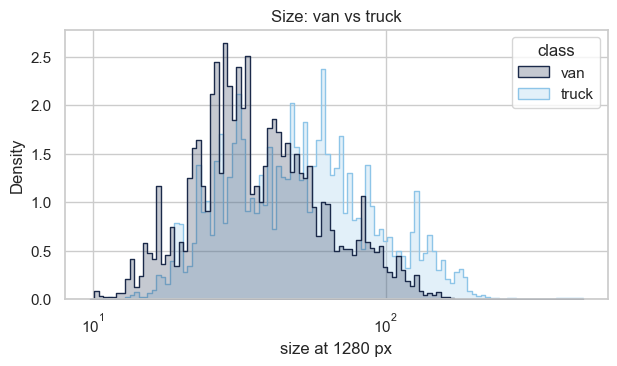

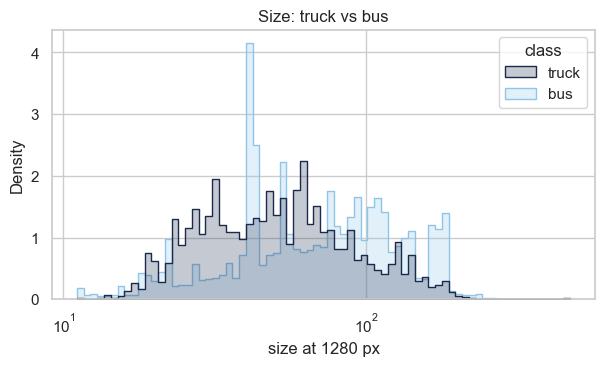

In [29]:
for pair in PAIRS:
    fig, ax = plt.subplots(figsize=(7, 3.5))
    sns.histplot(objects[objects["class"].isin(pair)], x="size_input", hue="class", hue_order=list(pair), log_scale=True, stat="density", common_norm=False, element="step", palette=[NAVY, LIGHT], ax=ax)
    ax.set(title=f"Size: {' vs '.join(pair)}", xlabel=f"size at {IMG_SIZE} px")
    plt.show()

These plots show for each pair, how often each size appears for the two classes. If the two lines lie on top of each other, the classes have the same sizes.

Car and van, bicycle and motor, and truck and bus have strongly overlapping size curves. Van and truck also overlap, trucks are only a bit bigger. So size alone cann't tell these classes apart.

## Objects per frame 

How many labelled objects there are in one frame. This tells how crowded the scenes are and how many boxes a model must be able to output.

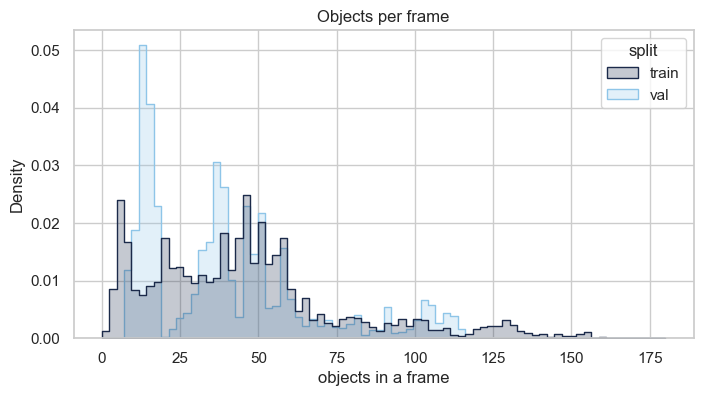

count    27047.0
mean        45.1
std         31.1
min          0.0
50%         42.0
90%         90.0
99%        140.0
max        180.0
Name: n_objects, dtype: float64

In [30]:
per_frame = objects.groupby("uid").size().reindex(images["uid"], fill_value=0)
density = images.assign(n_objects=per_frame.values)

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(density, x="n_objects", hue="split", stat="density", common_norm=False, element="step", palette=SPLIT_COLORS, ax=ax)
ax.set(title="Objects per frame", xlabel="objects in a frame")
plt.show()
density["n_objects"].describe(percentiles=[0.5, 0.9, 0.99]).round(1)

This plot shows how many frames have a given number of objects, separately for train and val.

A frame has 45 objects on average, 90 % of frames have up to 90 and the busiest has 180. 

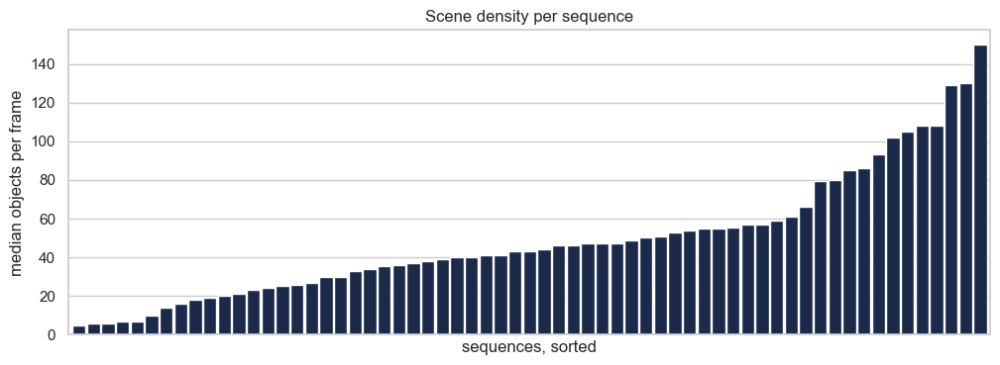

In [31]:
seq_density = density.groupby("video")["n_objects"].median().sort_values()

fig, ax = plt.subplots(figsize=(12, 4))
seq_density.plot.bar(color=NAVY, width=0.9, ax=ax)
ax.set(xticks=[], xlabel="sequences, sorted", ylabel="median objects per frame", title="Scene density per sequence")
plt.show()

Each bar is one video, the height is the median number of objects per frame in it. Videos are sorted from the emptiest to the most crowded.

Some videos have about 5 objects per frame and some more than 140, so videos are very different in difficulty.

## Variation across sequences

One row per video: frame width, number of objects, typical object size, share of small objects, number of frames, objects per frame and main class.

In [32]:
seq_stats = (
    objects.groupby("video")
    .agg(split=("split", "first"), width=("width", "first"), objects=("uid", "size"), median_size=("size", "median"), small_share=("coco_bucket", lambda s: (s == "small").mean()))
    .join(density.groupby("video").agg(frames=("uid", "size"), mean_per_frame=("n_objects", "mean")))
    .join(seq_class.idxmax(axis=1).rename("main_class"))
    .sort_values("mean_per_frame")
)
seq_stats["resolution"] = pd.cut(seq_stats["width"], [0, 1400, 2000, 4000], labels=["≤ 1360", "1904–1920", "≥ 2688"])
seq_stats.round(2)

,split,width,objects,median_size,small_share,frames,mean_per_frame,main_class,resolution
video,,,,,,,,,
uav0000218_00001_v,train,2688,1158,62.14,0.02,225,5.15,car,≥ 2688
uav0000266_04830_v,train,2688,706,81.58,0.00,116,6.09,person,≥ 2688
uav0000263_03289_v,train,1904,4686,54.85,0.12,725,6.46,truck,1904–1920
uav0000266_03598_v,train,2688,3548,80.92,0.00,548,6.47,car,≥ 2688
uav0000099_02109_v,train,1344,8955,37.08,0.29,1255,7.14,person,≤ 1360
...,...,...,...,...,...,...,...,...,...
uav0000150_02310_v,train,2688,37892,60.03,0.05,348,108.89,motor,≥ 2688
uav0000072_04488_v,train,1904,9382,45.83,0.15,85,110.38,person,1904–1920
uav0000124_00944_v,train,2688,49578,46.31,0.24,398,124.57,car,≥ 2688


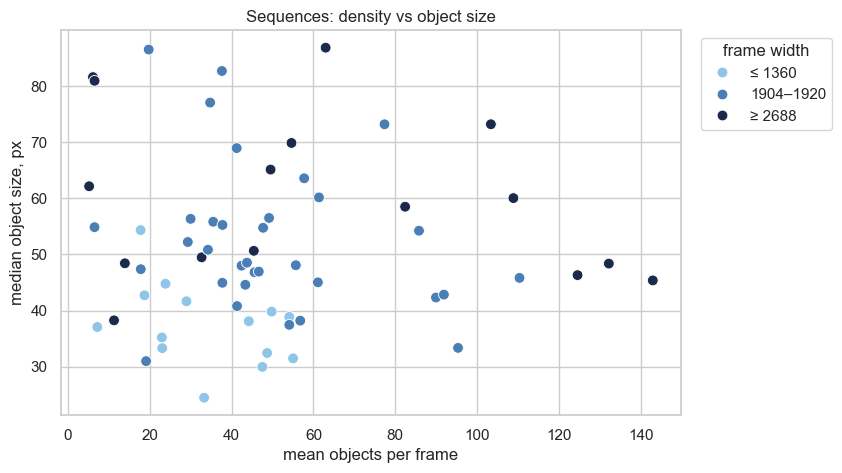

In [33]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(seq_stats, x="mean_per_frame", y="median_size", hue="resolution", palette=[LIGHT, MID, NAVY], s=60, ax=ax)
ax.legend(title="frame width", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set(title="Sequences: density vs object size", xlabel="mean objects per frame", ylabel="median object size, px")
plt.show()

Each dot is one video. The x-axis is the mean number of objects per frame, the y-axis the median object size, the colour the frame width.

Density and object size are not clearly related: both small and large objects appear in empty and in crowded videos. The smallest objects are mostly in the low-resolution videos (1360 px or less).

## Ignored regions: share of the frame

For each frame we measure which part of it is covered by ignored regions. Overlapping regions are counted only once.
A large share means a big part of the scene has no labels to learn from.

In [34]:
def ignored_fraction(row, regions, factor=8):
    mask = np.zeros((row.height // factor + 1, row.width // factor + 1), np.uint8)
    for r in regions.itertuples():
        mask[int(r.y) // factor:int(r.y + r.h) // factor + 1, int(r.x) // factor:int(r.x + r.w) // factor + 1] = 1
    return mask.mean()


ign_by_uid = dict(tuple(ignored.groupby("uid")))
density["ignored_share"] = [ignored_fraction(r, ign_by_uid[r.uid]) if r.uid in ign_by_uid else 0.0 for r in density.itertuples()]
density["ignored_share"].describe(percentiles=[0.5, 0.9, 0.99]).round(3)

count    27047.000
mean         0.025
std          0.040
min          0.000
50%          0.011
90%          0.064
99%          0.185
max          0.389
Name: ignored_share, dtype: float64

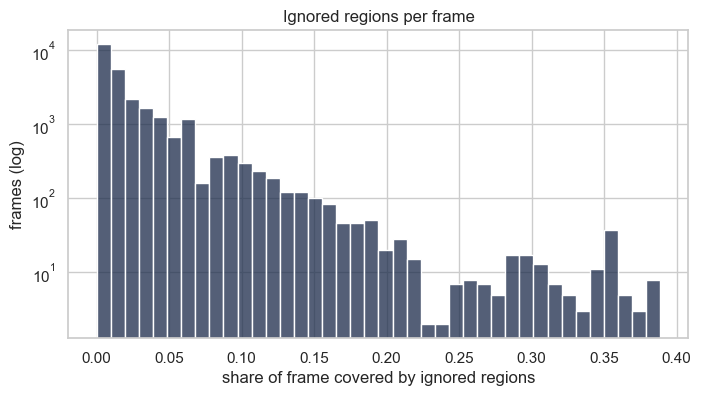

In [35]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(density, x="ignored_share", bins=40, color=NAVY, ax=ax)
ax.set(yscale="log", xlabel="share of frame covered by ignored regions", ylabel="frames (log)", title="Ignored regions per frame")
plt.show()

This plot shows how many frames have a given share covered by ignored regions. The y-axis is logarithmic because almost all frames have a small share.

In half of the frames at most 1 % of the area is ignored, but in the worst frame it is almost 40 %.

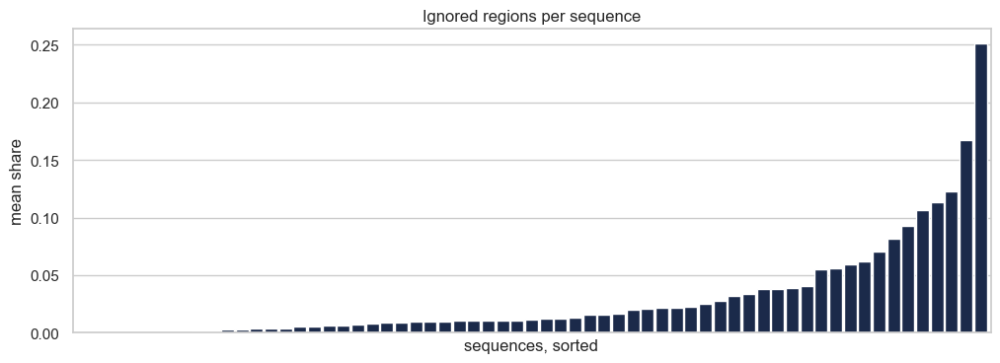

In [36]:
seq_ignored = density.groupby("video")["ignored_share"].mean().sort_values()

fig, ax = plt.subplots(figsize=(12, 4))
seq_ignored.plot.bar(color=NAVY, width=0.9, ax=ax)
ax.set(xticks=[], xlabel="sequences, sorted", ylabel="mean share", title="Ignored regions per sequence")
plt.show()

Each bar is one video, the height is the mean share of its frames covered by ignored regions. Videos are sorted from lowest to highest.

Most videos have very little ignored area. About 15 of 63 videos have more than 5 % of the frame ignored, and the worst one has 25 %.

## Brightness across sequences

For every 25th frame we compute the mean brightness (0 = black, 255 = white) and average it per video. Only train and val are used.

In [37]:
def mean_brightness(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    return cv2.resize(img, (160, 90), interpolation=cv2.INTER_AREA).mean()


bright_frames = images[(images["frame_id"] - 1) % 25 == 0].reset_index(drop=True)
bright_frames["brightness"] = [mean_brightness(DATA_DIR / s / f) for s, f in tqdm(zip(bright_frames["split"], bright_frames["file_name"]), total=len(bright_frames))]
seq_bright = bright_frames.groupby(["split", "video"])["brightness"].mean().reset_index()

100%|██████████| 1110/1110 [00:12<00:00, 92.21it/s] 


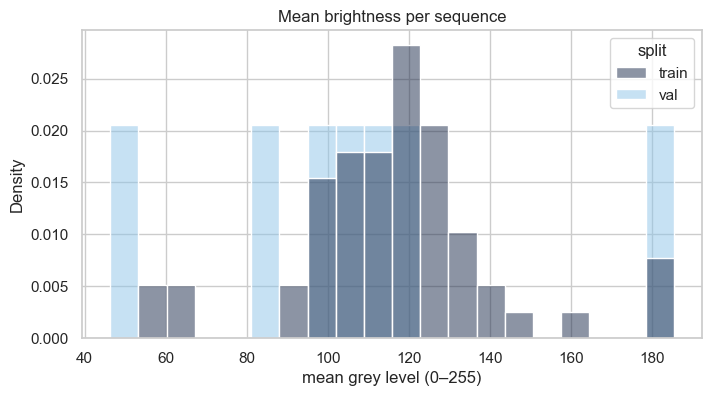

,count,mean,std,min,10%,50%,90%,max
split,,,,,,,,
train,56.0,116.2,25.5,58.5,94.8,116.4,139.6,182.0
val,7.0,107.6,42.2,46.4,68.9,104.2,146.8,185.4


In [38]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(seq_bright, x="brightness", hue="split", palette=SPLIT_COLORS, stat="density", common_norm=False, bins=20, ax=ax)
ax.set(title="Mean brightness per sequence", xlabel="mean grey level (0–255)")
plt.show()
seq_bright.groupby("split")["brightness"].describe(percentiles=[0.1, 0.5, 0.9]).round(1)

This plot shows, how many videos have a given mean brightness, separately for train and val.

Mean brightness goes from about 46 to 185, and val varies more than train. So lighting is very different between videos.

In [39]:
images = images.merge(seq_bright[["split", "video", "brightness"]], on=["split", "video"], how="left")
seq_bright.sort_values("brightness").head(10).round(1)

,split,video,brightness
57,val,uav0000117_02622_v,46.4
6,train,uav0000072_05448_v,58.5
4,train,uav0000071_03240_v,59.5
7,train,uav0000072_06432_v,60.4
5,train,uav0000072_04488_v,61.5
56,val,uav0000086_00000_v,84.0
17,train,uav0000145_00000_v,91.4
10,train,uav0000084_00000_v,94.4
2,train,uav0000013_01392_v,95.2
37,train,uav0000289_06922_v,96.2


## Temporal correlation and frame subsampling

Video has 25–30 frames per second, so neighbouring frames are almost the same. Training on all of them takes much more time but adds little new information.
To choose how often to take a frame, we follow every object (by its track id) and measure how much its box at frame t overlaps with its box at frame t + k.
Overlap is measured with IoU: 1 means the two boxes are identical, 0 means they do not touch.

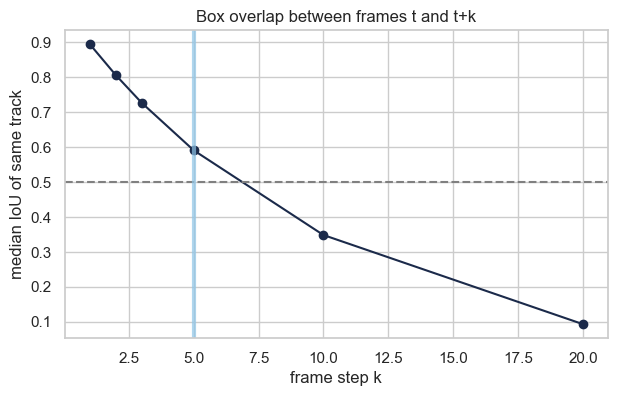

1     0.895
2     0.806
3     0.727
5     0.591
10    0.348
20    0.093
Name: median_iou, dtype: float64

In [40]:
def track_iou(df, k):
    nxt = df.assign(frame_id=df["frame_id"] - k)
    m = df.merge(nxt, on=["video", "track_id", "frame_id"], suffixes=("", "_k"))
    iw = (np.minimum(m["x"] + m["w"], m["x_k"] + m["w_k"]) - np.maximum(m["x"], m["x_k"])).clip(0)
    ih = (np.minimum(m["y"] + m["h"], m["y_k"] + m["h_k"]) - np.maximum(m["y"], m["y_k"])).clip(0)
    inter = iw * ih
    return inter / (m["w"] * m["h"] + m["w_k"] * m["h_k"] - inter)


STEP = 5
steps = [1, 2, 3, 5, 10, 20]
iou_by_step = pd.Series({k: track_iou(objects, k).median() for k in steps}, name="median_iou")

fig, ax = plt.subplots(figsize=(7, 4))
iou_by_step.plot(marker="o", color=NAVY, ax=ax)
ax.axhline(0.5, color="grey", ls="--")
ax.axvline(STEP, color=LIGHT, lw=3, alpha=0.7)
ax.set(xlabel="frame step k", ylabel="median IoU of same track", title="Box overlap between frames t and t+k")
plt.show()
iou_by_step.round(3)

This plot shows for each frame step k, the median overlap (IoU) between the box of the same object at frame t and at frame t + k. The grey dashed line is IoU 0.5, the blue line is the chosen step.

The same object has IoU 0.90 after 1 frame, 0.59 after 5 and only 0.35 after 10. Every 5th frame still gives new information but skips almost identical frames.

In [41]:
images["keep"] = (images["frame_id"] - 1) % STEP == 0
images.groupby("split")["keep"].agg(["size", "sum"])

,size,sum
split,,
train,24201,4868
val,2846,571


## Anchor statistics

Anchor-based detectors (Faster R-CNN, RetinaNet) start from a set of template boxes called anchors and adjust them to the objects.
If the templates are much larger than the objects, small objects are missed. We find 9 typical box shapes in our training data with k-means
(boxes are grouped by how well they overlap, as in YOLOv2), after resizing frames to the input size.

In [42]:
def wh_iou(wh, centers):
    inter = np.minimum(wh[:, None, 0], centers[None, :, 0]) * np.minimum(wh[:, None, 1], centers[None, :, 1])
    return inter / (wh.prod(1)[:, None] + centers.prod(1)[None] - inter)


def iou_kmeans(wh, k, iters=100):
    rng = np.random.default_rng(SEED)
    centers = wh[rng.choice(len(wh), k, replace=False)]
    for _ in range(iters):
        assign = wh_iou(wh, centers).argmax(1)
        new = np.array([np.median(wh[assign == i], axis=0) for i in range(k)])
        if np.allclose(new, centers):
            break
        centers = new
    return centers[np.argsort(centers.prod(1))], wh_iou(wh, centers).max(1).mean()


train_obj = objects[objects["split"] == "train"]
scale = IMG_SIZE / np.maximum(train_obj["width"], train_obj["height"])
wh = np.stack([train_obj["w"] * scale, train_obj["h"] * scale], axis=1)
sample = wh[np.random.default_rng(SEED).choice(len(wh), min(len(wh), 100_000), replace=False)]

anchors, mean_iou = iou_kmeans(sample, 9)
print(f"mean best IoU: {mean_iou:.3f}")
pd.DataFrame(anchors.round(1), columns=["w", "h"]).assign(size=lambda d: np.sqrt(d.w * d.h).round(1), ratio=lambda d: (d.h / d.w).round(2))

mean best IoU: 0.727


,w,h,size,ratio
0,10.8,16.0,13.1,1.48
1,20.8,18.8,19.8,0.90
2,14.8,29.5,20.9,1.99
3,34.3,24.9,29.2,0.73
4,22.9,39.0,29.9,1.70
5,55.8,31.6,42.0,0.57
6,39.0,52.4,45.2,1.34
7,82.9,51.1,65.1,0.62
8,113.6,92.1,102.3,0.81


## Sequence-level folds

Frames from the same video are very similar, so if one frame of a video is in train and another in validation, the score would be too optimistic.
That is why we split by video, not by frame: every video goes into exactly one of 5 folds.
We pool train and val (63 videos), because the official val has a different class mix than train. All later models use the same folds.

In [43]:
seq_frames = images.groupby("video").size()
fold_of = {}
for fold, (_, val_idx) in enumerate(GroupKFold(n_splits=5).split(seq_frames.index, groups=seq_frames.index)):
    fold_of.update({v: fold for v in seq_frames.index[val_idx]})

images["fold"] = images["video"].map(fold_of)
objects["fold"] = objects["video"].map(fold_of)

fold_class = pd.crosstab(objects["fold"], objects["class"], normalize="index")[CLASSES]

In [44]:
fold_stats = images.groupby("fold").agg(sequences=("video", "nunique"), frames=("uid", "size")).join(objects.groupby("fold").size().rename("objects"))
fold_class = pd.crosstab(objects["fold"], objects["class"], normalize="index")[CLASSES].round(3)
fold_stats.join(fold_class)

,sequences,frames,objects,person,bicycle,car,van,truck,tricycle,bus,motor
fold,,,,,,,,,,,
0,13,6021,270234,0.313,0.028,0.469,0.061,0.015,0.031,0.006,0.077
1,13,5231,298726,0.267,0.038,0.515,0.028,0.031,0.020,0.015,0.086
2,13,5352,217377,0.277,0.015,0.470,0.053,0.034,0.068,0.010,0.073
3,12,5368,160501,0.331,0.030,0.419,0.046,0.056,0.031,0.006,0.082
4,12,5075,272810,0.372,0.070,0.320,0.037,0.008,0.046,0.003,0.144


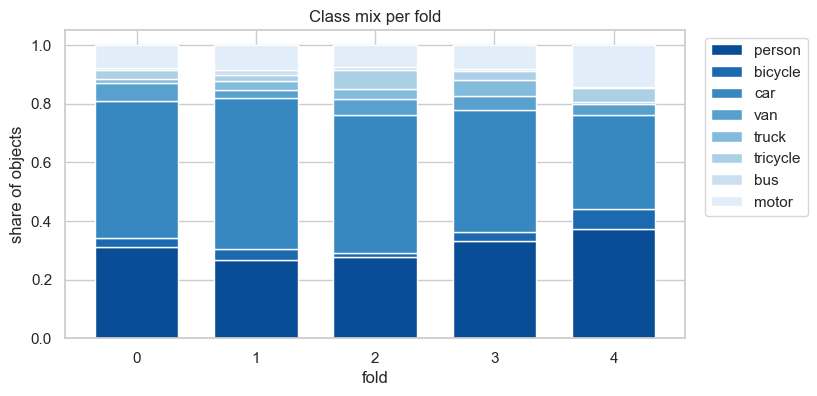

In [45]:
ax = fold_class.plot.bar(stacked=True, color=sns.color_palette("Blues_r", len(CLASSES)), figsize=(8, 4), rot=0, width=0.7)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set(ylabel="share of objects", title="Class mix per fold")
plt.show()

Each bar is one fold, the coloured parts are the shares of each class among its objects.

Cars are 32 % of objects in fold 4 and 52 % in fold 1. So folds are not equally hard, and we look at the mean over all folds.

## Conversion to YOLO and COCO

Here we create the data the models will be trained on. For every 5th frame we:

- fill ignored regions with grey, so the model does not learn from areas without labels;
- make the frame smaller if its longer side is above 1920 px (test frames are at most 1920 px, so we lose nothing);
- save the boxes in two formats: YOLO text files (one file per frame, used by Ultralytics) and COCO json files (used by torchvision and by the evaluation tool).

In the COCO files ignored regions are kept and marked with iscrowd = 1. The evaluation tool then ignores detections inside them: they count neither as correct nor as mistakes.

Frames and labels are saved once. A fold is just a list of which frames go to train and which go to validation.

In [46]:
IMG_DIR = OUT_DIR / "images"
LBL_DIR = OUT_DIR / "labels"
IMG_DIR.mkdir(parents=True, exist_ok=True)
LBL_DIR.mkdir(parents=True, exist_ok=True)


def export_frame(row, frame_objects, frame_ignored):
    img = cv2.imread(str(DATA_DIR / row.split / row.file_name))
    for r in frame_ignored.itertuples():
        cv2.rectangle(img, (int(r.x), int(r.y)), (int(r.x + r.w), int(r.y + r.h)), IGNORE_COLOR, -1)
    s = min(1.0, 1920 / max(row.width, row.height))
    if s < 1:
        img = cv2.resize(img, (round(row.width * s), round(row.height * s)), interpolation=cv2.INTER_AREA)
    name = f"{row.video}_{row.frame_id:07d}"
    cv2.imwrite(str(IMG_DIR / f"{name}.jpg"), img, [cv2.IMWRITE_JPEG_QUALITY, 95])

    x1, y1 = frame_objects["x"].clip(0, row.width), frame_objects["y"].clip(0, row.height)
    x2, y2 = (frame_objects["x"] + frame_objects["w"]).clip(0, row.width), (frame_objects["y"] + frame_objects["h"]).clip(0, row.height)
    valid = (x2 - x1 >= 1) & (y2 - y1 >= 1)
    yolo = pd.DataFrame({"cls": frame_objects["cls"], "xc": (x1 + x2) / 2 / row.width, "yc": (y1 + y2) / 2 / row.height, "w": (x2 - x1) / row.width, "h": (y2 - y1) / row.height})[valid]
    yolo.to_csv(LBL_DIR / f"{name}.txt", sep=" ", header=False, index=False, float_format="%.6f")
    return name, img.shape[1], img.shape[0], s

In [47]:
kept = images[images["keep"]].reset_index(drop=True)
obj_by_uid = dict(tuple(objects.groupby("uid")))
empty = objects.iloc[:0]

exported = [export_frame(row, obj_by_uid.get(row.uid, empty), ign_by_uid.get(row.uid, empty)) for row in tqdm(kept.itertuples(), total=len(kept))]
kept[["name", "exp_width", "exp_height", "scale"]] = pd.DataFrame(exported)

100%|██████████| 5439/5439 [01:01<00:00, 87.86it/s] 


What is saved in data_prepared:

- images: the prepared frames;
- labels: YOLO labels, one text file per frame (class, box centre, width, height);
- coco: fold0_train.json, fold0_val.json and the same for folds 1–4 (for torchvision models and for computing mAP);
- fold0.yaml, fold0_train.txt, fold0_val.txt and the same for folds 1–4 (for Ultralytics models);
- folds.csv: which fold every video belongs to;
- preprocess.yaml: the settings shared by all models.

All paths inside are relative, so the folder works on any computer. Ultralytics needs the full path to the yaml file, for example str((OUT_DIR / "fold0.yaml").resolve()).
The YOLO lists are kept next to the images folder because Ultralytics looks for the images relative to the list file.

In [48]:
def to_coco(frames):
    sub = anns[anns["uid"].isin(frames["uid"])].merge(frames[["uid", "scale"]], on="uid")
    imgs = [{"id": i, "file_name": f"images/{r.name}.jpg", "width": r.exp_width, "height": r.exp_height, "video": r.video, "frame_id": r.frame_id} for i, r in enumerate(frames.itertuples(), 1)]
    img_id = dict(zip(frames["uid"], range(1, len(frames) + 1)))
    coco_anns = [
        {"id": i, "image_id": img_id[r.uid], "category_id": int(r.category_id), "bbox": [r.x * r.scale, r.y * r.scale, r.w * r.scale, r.h * r.scale], "area": r.w * r.h * r.scale ** 2, "iscrowd": int(r.ignore)}
        for i, r in enumerate(sub.itertuples(), 1)
    ]
    return {"images": imgs, "annotations": coco_anns, "categories": [{"id": i + 1, "name": c} for i, c in enumerate(CLASSES)]}


(OUT_DIR / "coco").mkdir(exist_ok=True)
for fold in range(5):
    for part, frames in [("train", kept[kept["fold"] != fold]), ("val", kept[kept["fold"] == fold])]:
        (OUT_DIR / f"fold{fold}_{part}.txt").write_text("\n".join(f"./images/{n}.jpg" for n in frames["name"]))
        (OUT_DIR / "coco" / f"fold{fold}_{part}.json").write_text(json.dumps(to_coco(frames)))
    yaml.safe_dump({"train": f"fold{fold}_train.txt", "val": f"fold{fold}_val.txt", "nc": len(CLASSES), "names": CLASSES}, open(OUT_DIR / f"fold{fold}.yaml", "w"), sort_keys=False)

images[["uid", "split", "video", "frame_id", "fold", "keep", "brightness"]].to_csv(OUT_DIR / "folds.csv", index=False)

## Verify the conversion

In [49]:
n_labels = sum(len(open(LBL_DIR / f"{n}.txt").read().splitlines()) for n in kept["name"])
n_objects = objects["uid"].isin(kept["uid"]).sum()
print(f"objects in kept frames: {n_objects}, exported labels: {n_labels}, dropped degenerate: {n_objects - n_labels}")

objects in kept frames: 245785, exported labels: 245785, dropped degenerate: 0


Boxes are drawn from the saved YOLO labels, not from the original file, so this checks that the conversion itself is correct. Grey areas are ignored regions.

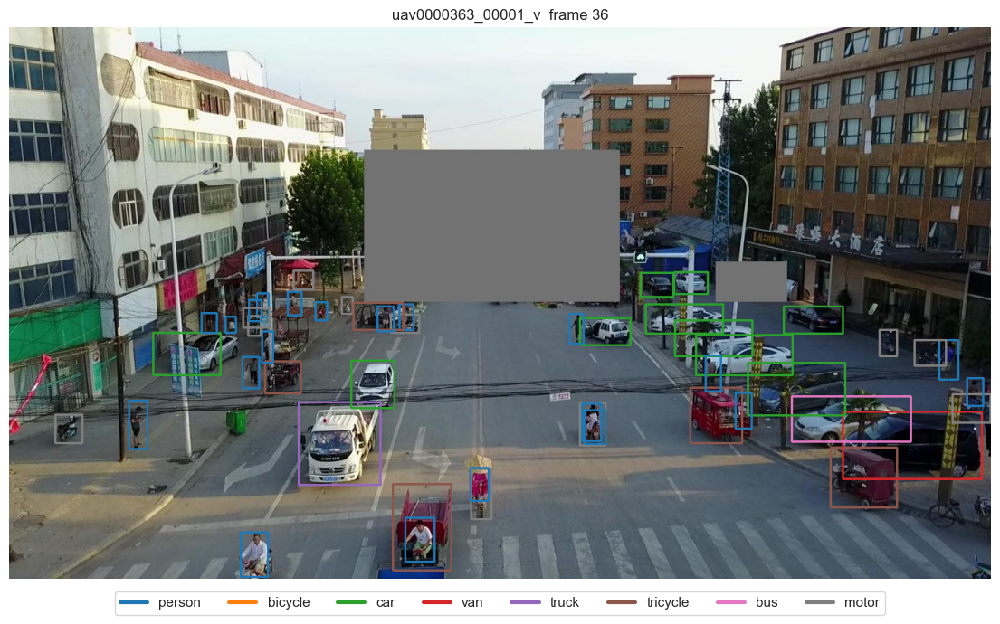

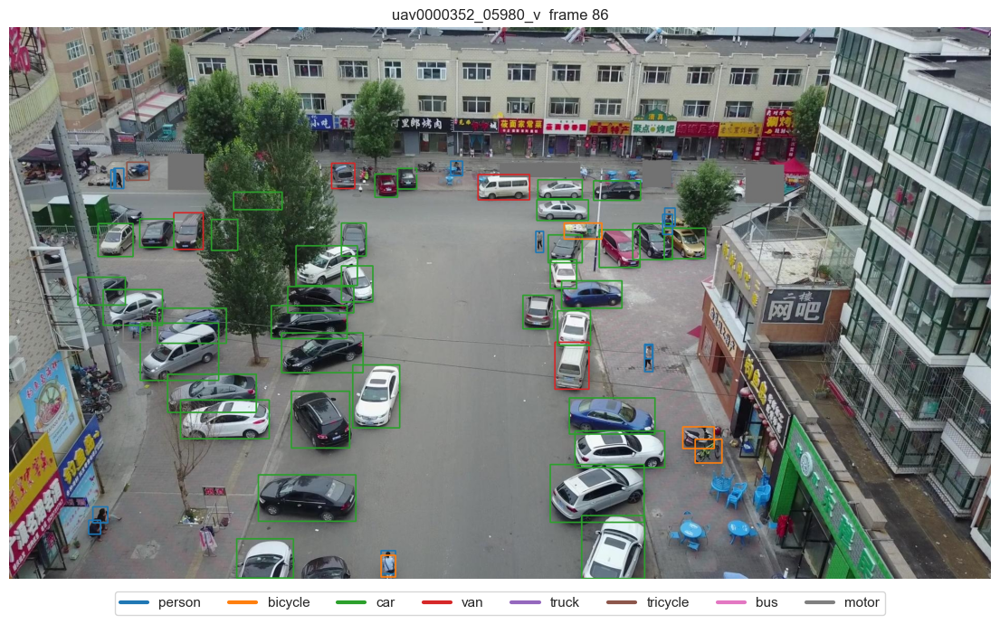

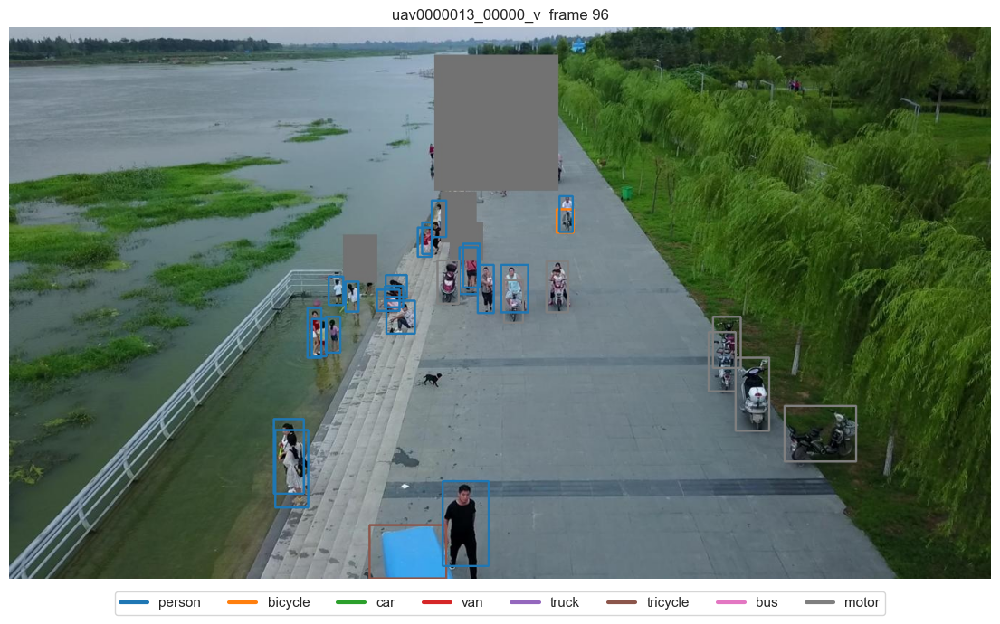

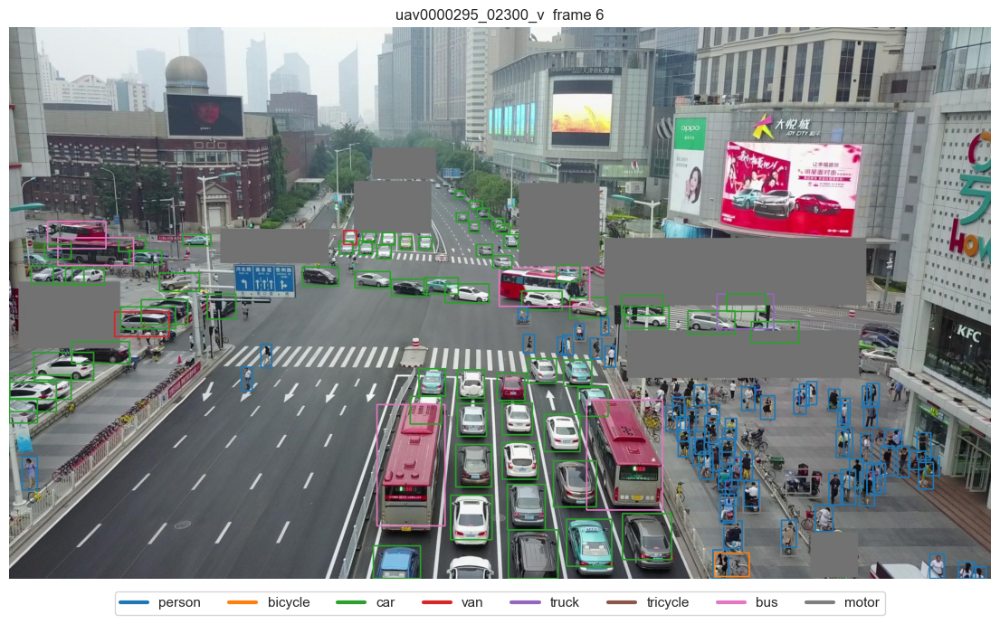

In [50]:
LEGEND = [plt.Line2D([], [], color=c, lw=3, label=n) for c, n in zip(CLASS_COLORS, CLASSES)]


def draw_yolo(name):
    img = cv2.cvtColor(cv2.imread(str(IMG_DIR / f"{name}.jpg")), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    for line in open(LBL_DIR / f"{name}.txt").read().splitlines():
        c, xc, yc, w, h = map(float, line.split())
        color = tuple(int(255 * v) for v in CLASS_COLORS[int(c)])
        cv2.rectangle(img, (int((xc - w / 2) * W), int((yc - h / 2) * H)), (int((xc + w / 2) * W), int((yc + h / 2) * H)), color, 2)
    return img


samples = kept.groupby("video").sample(1, random_state=SEED).sample(4, random_state=SEED)
for r in samples.itertuples():
    fig, ax = plt.subplots(figsize=(14, 8))
    ax.imshow(draw_yolo(r.name))
    ax.set_title(f"{r.video}  frame {r.frame_id}")
    ax.axis("off")
    ax.legend(handles=LEGEND, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=8)
    plt.show()

All 245,785 objects in the kept frames were exported and none were dropped. On the sample frames the boxes sit on the objects and ignored areas are grey.

## Resizing, normalization and augmentation

These settings are saved once and used by every model during training.

Resizing: the frame is made smaller so its longer side is 1280 px, and the rest is filled with grey to get a 1280 × 1280 square (the shape is not stretched).

Normalization: the pretrained models were trained on ImageNet, where every pixel was changed with (pixel / 255 − mean) / std.
mean and std are the average colour and its spread in ImageNet, one value per colour channel. We do not compute them, they are the standard ImageNet values.
Torchvision models apply this inside the model, Ultralytics only divides by 255. We write the values down to describe the setup.

Augmentation: small random changes of a frame during training, so the model learns objects and not exact pictures.
Every augmentation has its own probability and is chosen independently for every frame and every epoch, so one frame may get flip and zoom, another only brightness, another nothing.

- Horizontal flip (probability 0.5): keeps the perspective, so the frame still looks real. Vertical flip is not used (see the perspective plot).
- Zoom-in, random crop (0.5): a part of the frame (25–100 % of its area) is cut out and enlarged to 1280 px, so small objects look bigger.
- Stronger brightness, contrast and gamma (0.5): brightness differs a lot between videos.
- Copy-paste of rare classes (0.3): trucks and buses from other frames are pasted into the frame.

In [51]:
PREPROCESS = {
    "seed": SEED,
    "frame_step": STEP,
    "export_max_side": 1920,
    "img_size": IMG_SIZE,
    "mean": [0.485, 0.456, 0.406],
    "std": [0.229, 0.224, 0.225],
    "augment": {
        "hflip": 0.5,
        "crop": {"p": 0.5, "area": [0.25, 1.0]},
        "brightness_contrast": {"p": 0.5, "limit": 0.4},
        "gamma": {"p": 0.5, "limit": [60, 140]},
        "copy_paste": {"p": 0.3, "classes": ["truck", "bus"], "per_frame": 3},
    },
}
yaml.safe_dump(PREPROCESS, open(OUT_DIR / "preprocess.yaml", "w"), sort_keys=False)

In [52]:
aug = PREPROCESS["augment"]
BBOX_PARAMS = A.BboxParams(format="yolo", label_fields=["labels"], min_visibility=0.3)
letterbox = A.Sequential([A.LongestMaxSize(max_size=IMG_SIZE), A.PadIfNeeded(IMG_SIZE, IMG_SIZE, border_mode=cv2.BORDER_CONSTANT, fill=IGNORE_COLOR)])
zoom = A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=tuple(aug["crop"]["area"]), ratio=(0.9, 1.1), p=1)

train_transform = A.Compose(
    [
        A.OneOf([zoom, letterbox], p=1),
        A.HorizontalFlip(p=aug["hflip"]),
        A.RandomBrightnessContrast(brightness_limit=aug["brightness_contrast"]["limit"], contrast_limit=aug["brightness_contrast"]["limit"], p=aug["brightness_contrast"]["p"]),
        A.RandomGamma(gamma_limit=tuple(aug["gamma"]["limit"]), p=aug["gamma"]["p"]),
    ],
    bbox_params=BBOX_PARAMS,
    seed=SEED,
)

Copy-paste takes truck and bus boxes from other training frames of fold 0. A pasted object keeps its height in the frame, so its size still fits the perspective.
It is skipped if it would overlap another object or a grey ignored region. It can still land on a building or a roof, because the code does not know where the road is.

In [53]:
rare_ids = [CLASSES.index(c) for c in aug["copy_paste"]["classes"]]
rare_pool = (
    objects[objects["cls"].isin(rare_ids) & objects["uid"].isin(kept.loc[kept["fold"] != 0, "uid"])]
    .merge(kept[["uid", "name", "scale", "exp_width", "exp_height"]], on="uid")
)


def overlaps(box, boxes):
    x1, y1, x2, y2 = box
    return any(x1 < bx2 and bx1 < x2 and y1 < by2 and by1 < y2 for bx1, by1, bx2, by2 in boxes)


def copy_paste(img, lbl, rng, n=aug["copy_paste"]["per_frame"]):
    img, lbl = img.copy(), lbl.copy()
    H, W = img.shape[:2]
    boxes = [((xc - w / 2) * W, (yc - h / 2) * H, (xc + w / 2) * W, (yc + h / 2) * H) for _, xc, yc, w, h in lbl]
    for r in rare_pool.iloc[rng.choice(len(rare_pool), min(n, len(rare_pool)), replace=False)].itertuples():
        src = cv2.cvtColor(cv2.imread(str(IMG_DIR / f"{r.name}.jpg")), cv2.COLOR_BGR2RGB)
        x, y, w, h = (int(v * r.scale) for v in (r.x, r.y, r.w, r.h))
        k = W / r.exp_width
        patch = cv2.resize(src[y:y + h, x:x + w], (max(1, round(w * k)), max(1, round(h * k))))
        ph, pw = patch.shape[:2]
        ty = int(np.clip((y + h / 2) / r.exp_height * H - ph / 2, 0, H - ph))
        tx = int(rng.integers(0, W - pw))
        region = img[ty:ty + ph, tx:tx + pw].astype(int)
        grey_share = (np.abs(region - IGNORE_COLOR).max(axis=2) <= 3).mean()
        if overlaps((tx, ty, tx + pw, ty + ph), boxes) or grey_share > 0.05:
            continue
        img[ty:ty + ph, tx:tx + pw] = patch
        boxes.append((tx, ty, tx + pw, ty + ph))
        lbl = np.vstack([lbl, [r.cls, (tx + pw / 2) / W, (ty + ph / 2) / H, pw / W, ph / H]])
    return img, lbl


def augment(img, lbl, rng):
    if rng.random() < aug["copy_paste"]["p"]:
        img, lbl = copy_paste(img, lbl, rng)
    out = train_transform(image=img, bboxes=lbl[:, 1:], labels=lbl[:, 0])
    return out["image"], np.asarray(out["bboxes"]), np.asarray(out["labels"])

Below: 
- the original frame, 
- then every augmentation on its own, 
- then random combinations as they would happen in training.

 Boxes are drawn on every picture to show that they move together with the image.

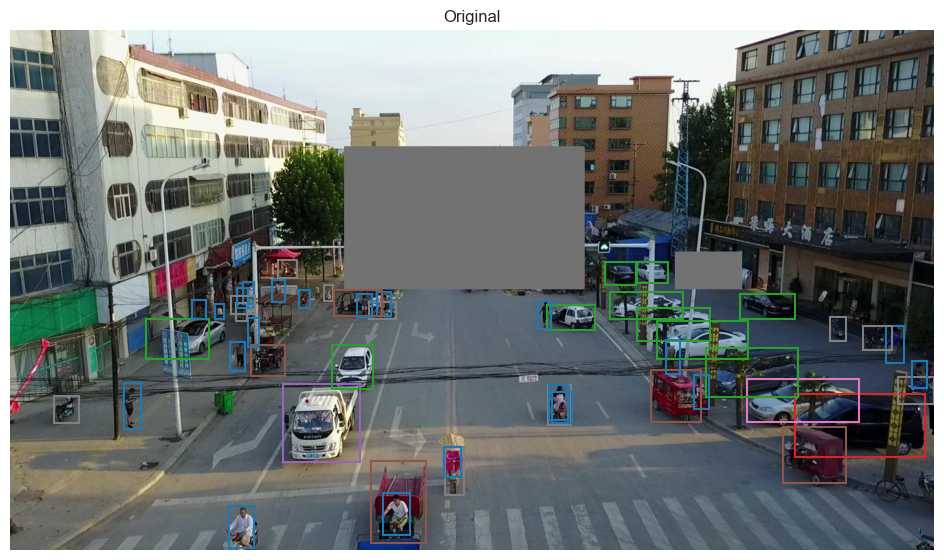

In [54]:
def show(img, boxes, labels, title):
    H, W = img.shape[:2]
    fig, ax = plt.subplots(figsize=(12, 12 * H / W))
    ax.imshow(img)
    for (xc, yc, w, h), c in zip(boxes, labels):
        ax.add_patch(plt.Rectangle(((xc - w / 2) * W, (yc - h / 2) * H), w * W, h * H, fill=False, color=CLASS_COLORS[int(c)], lw=1.5))
    ax.set_title(title)
    ax.axis("off")
    plt.show()


name = samples["name"].iloc[0]
img = cv2.cvtColor(cv2.imread(str(IMG_DIR / f"{name}.jpg")), cv2.COLOR_BGR2RGB)
lbl = np.loadtxt(LBL_DIR / f"{name}.txt", ndmin=2)
show(img, lbl[:, 1:], lbl[:, 0], "Original")

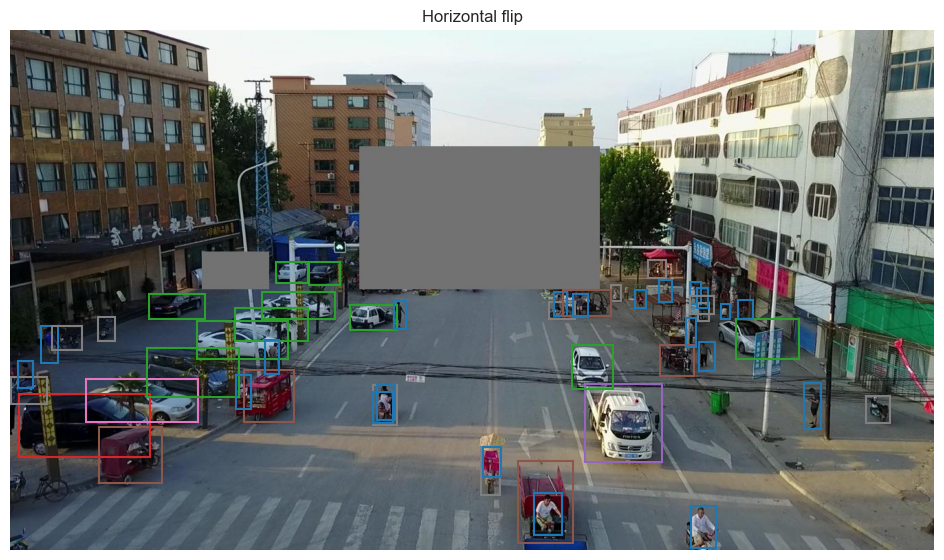

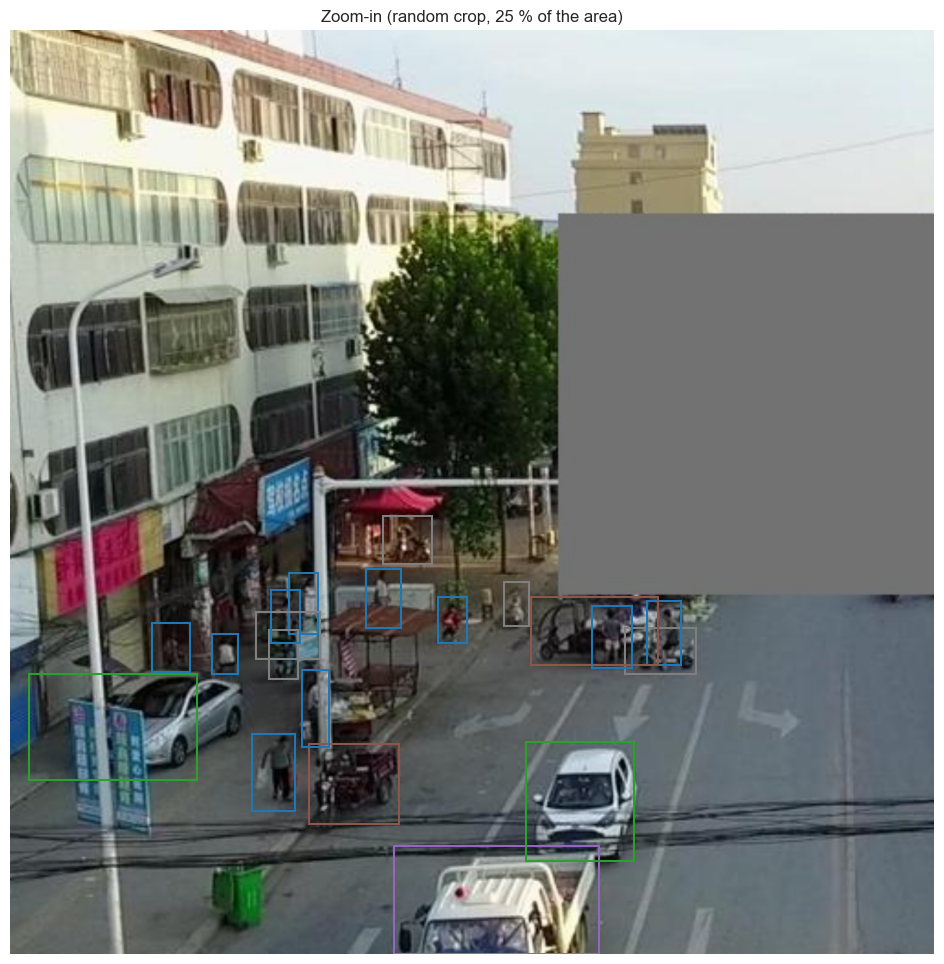

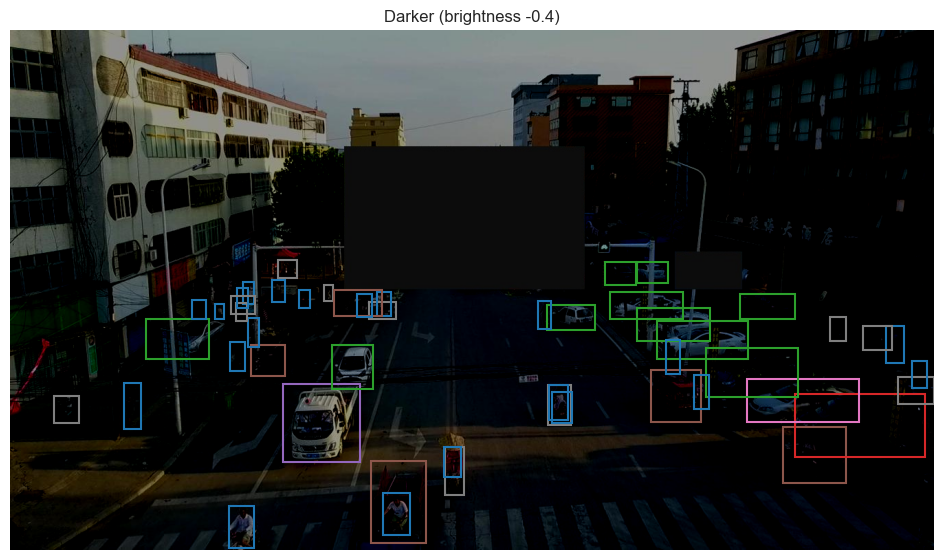

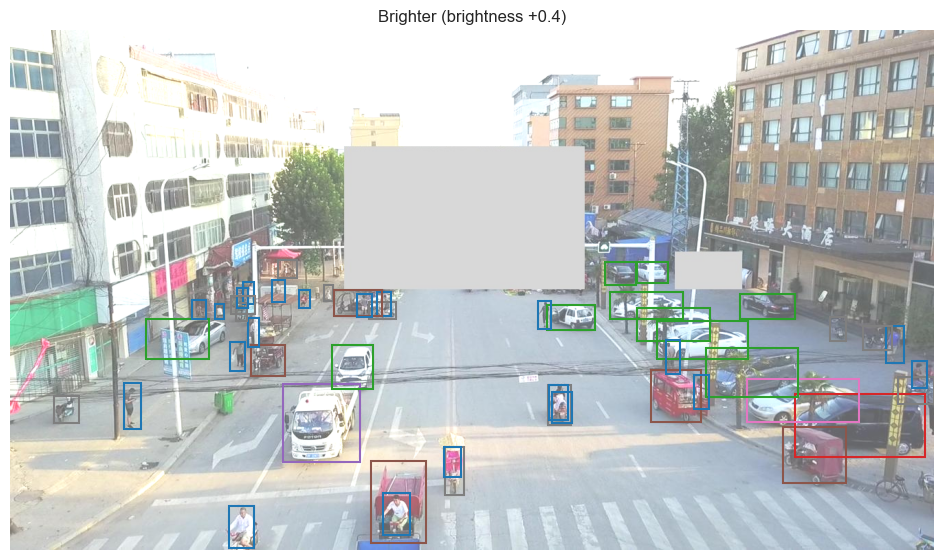

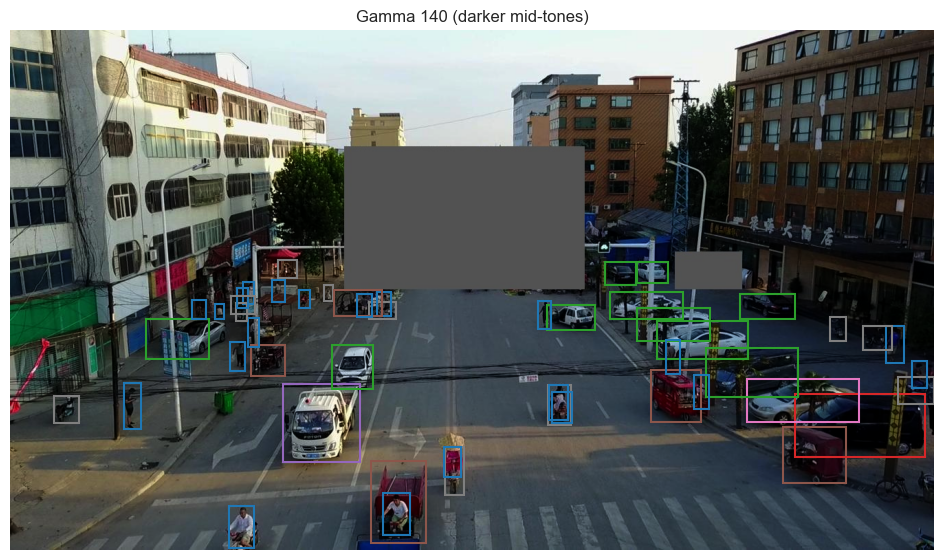

In [55]:
single = {
    "Horizontal flip": A.HorizontalFlip(p=1),
    "Zoom-in (random crop, 25 % of the area)": A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.25, 0.25), ratio=(1, 1), p=1),
    "Darker (brightness -0.4)": A.RandomBrightnessContrast(brightness_limit=(-0.4, -0.4), contrast_limit=(0, 0), p=1),
    "Brighter (brightness +0.4)": A.RandomBrightnessContrast(brightness_limit=(0.4, 0.4), contrast_limit=(0, 0), p=1),
    "Gamma 140 (darker mid-tones)": A.RandomGamma(gamma_limit=(140, 140), p=1),
}
for title, t in single.items():
    params = BBOX_PARAMS if isinstance(t, (A.HorizontalFlip, A.RandomResizedCrop)) else None
    out = A.Compose([t], bbox_params=params, seed=SEED)(image=img, bboxes=lbl[:, 1:], labels=lbl[:, 0])
    show(out["image"], out.get("bboxes", lbl[:, 1:]), out.get("labels", lbl[:, 0]), title)

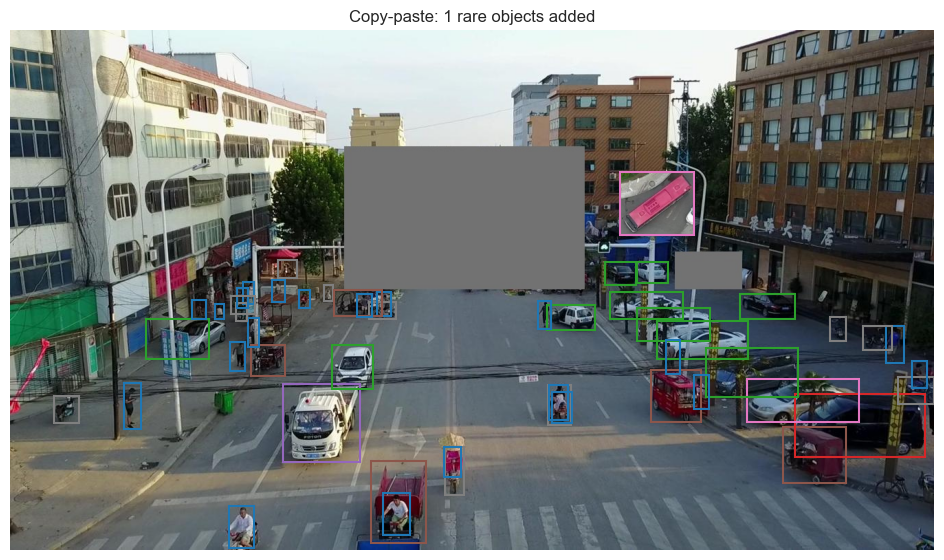

In [56]:
rng = np.random.default_rng(SEED)
cp_img, cp_lbl = copy_paste(img, lbl, rng, n=6)
show(cp_img, cp_lbl[:, 1:], cp_lbl[:, 0], f"Copy-paste: {len(cp_lbl) - len(lbl)} rare objects added")

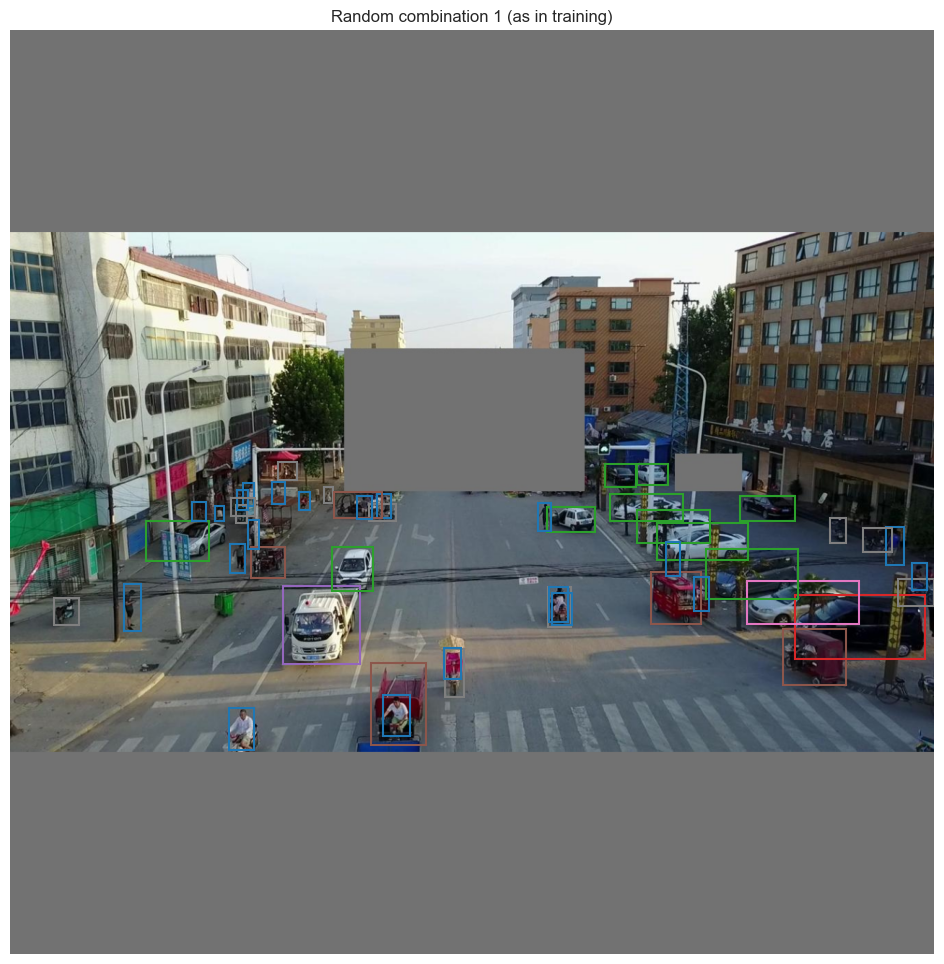

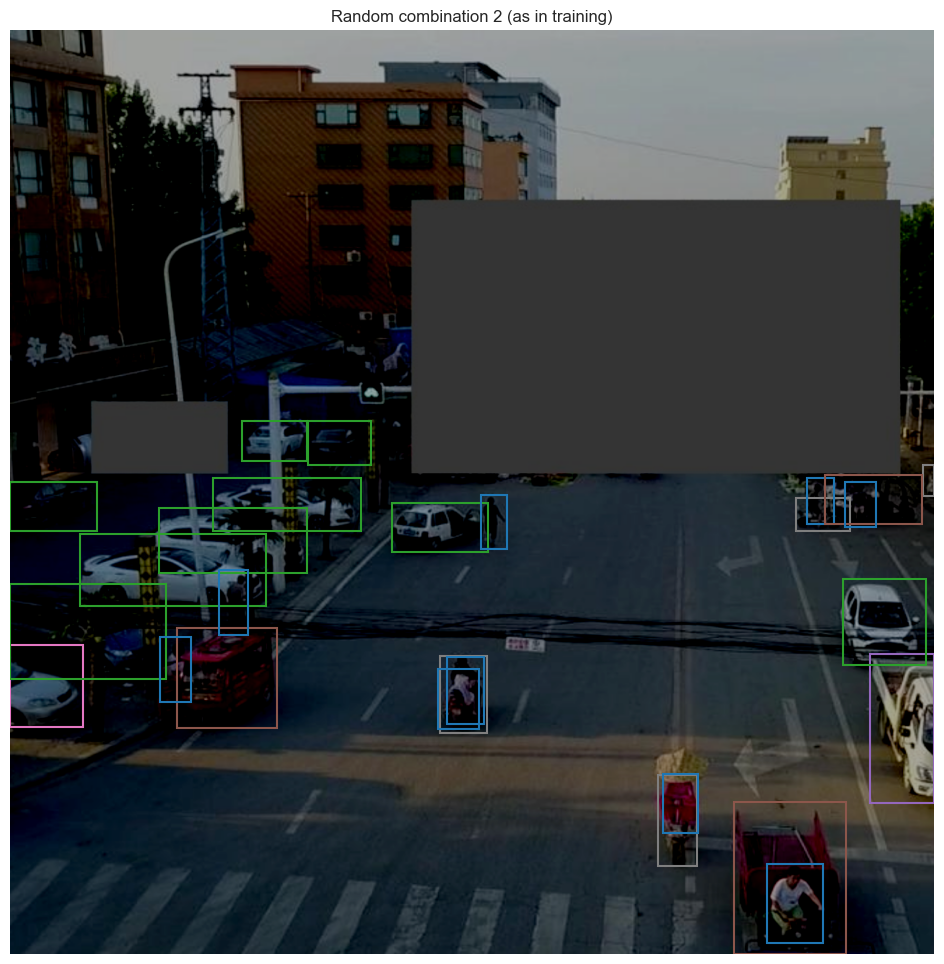

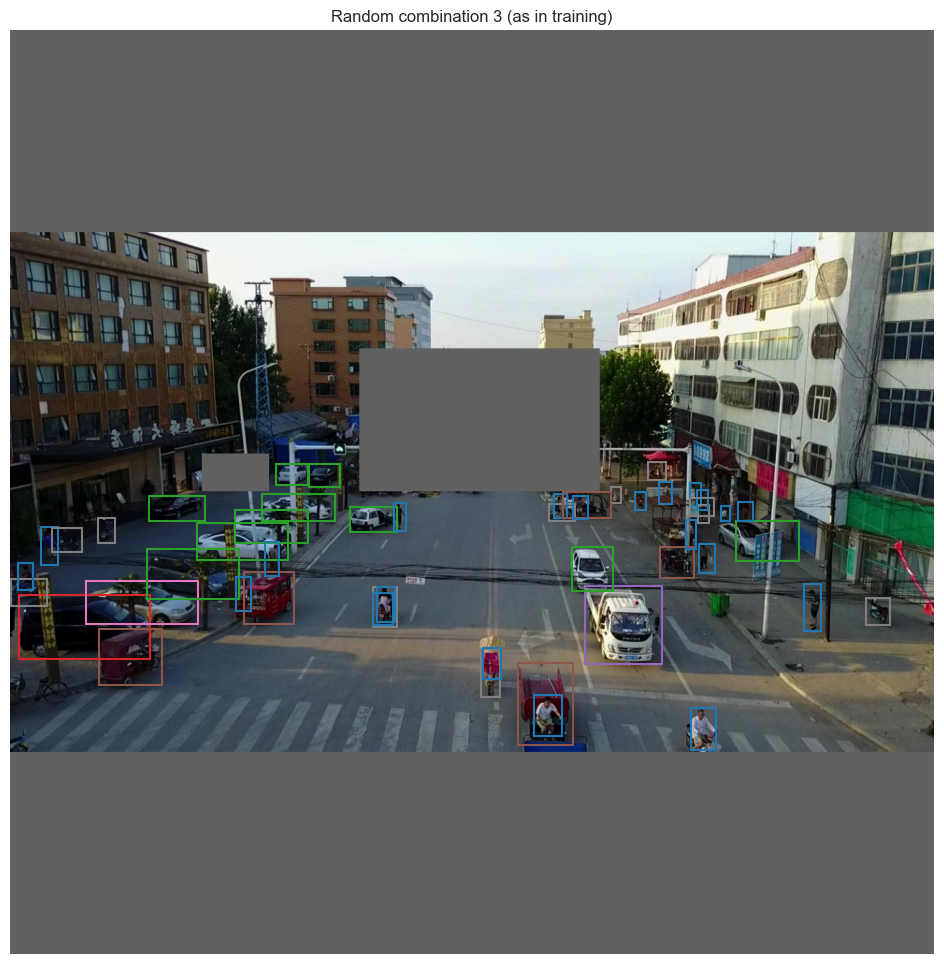

In [57]:
for i in range(3):
    a_img, a_boxes, a_labels = augment(img, lbl, rng)
    show(a_img, a_boxes, a_labels, f"Random combination {i + 1} (as in training)")

In the first and third combinations the frame was not zoomed, so it was padded with grey to a square, and the third one is a mirror image of the first because of the horizontal flip, while in the second combination we got a zoom-in on part of the frame together with a strong darkening, and in all three cases the boxes moved together with the image.

## Observations

1. The classes are very unbalanced. Cars are almost half of all objects in train 46 % and people are about 30 %, but buses are less than 1 % and trucks about 3 %. So the model will see very few buses and trucks and we added copy-paste of trucks and buses to give it more examples.

2. The official val has a different class mix than train and its frames are much bigger (34 % of val frames are 3000 px or wider, while test frames are at most 1920 px). Because of this we joined train and val and made our own folds by video.

3. The mean brightness of videos goes from about 46 to 185, so some videos are very dark and some are very bright. That is why we use stronger brightness, contrast and gamma augmentation.

4. At 640 px more than half of objects would be smaller than 16 px, at 1280 px only about 10 %. So we train at 1280 px (960 px only for the cheaper cv experiments), and we also use zoom-in crops so small objects look bigger.

5. Most videos are filmed at an angle, so objects at the top of the frame are smaller than at the bottom. A horizontal flip keeps this, a vertical flip would put small far objects at the bottom, which never happens in real frames. So we use only horizontal flip.

6. K-means on the box sizes at 1280 px gives 9 typical boxes from about 13 px to 102 px and the smallest one is only 13 px. The default anchors start at 32 px, so many small objects have no good anchor. 

7. On average there are 45 objects in a frame, but 99 % of frames have up to 140 and the busiest one has 180. So we let the models output up to 500 boxes per frame.

8. Car and van, bicycle and motor, truck and bus have very similar sizes, so size alone does not tell them apart. We expect the models to mix these classes up, and we check this in the failure cases.

9. On average only 2.5 % of a frame is ignored, but in some frames it is almost 40 %. We fill these areas with grey so the model doesn't learn them as background, and in the COCO files we keep them as iscrowd = 1 so detections there aren't counted as mistakes.

10. Augmentations chosen and why: horizontal flip (perspective), zoom-in crop (small objects), brightness, contrast and gamma (very different lighting), copy-paste of trucks and buses (rare classes).

11. The same object overlaps with itself with IoU 0.59 after 5 frames and only 0.35 after 10 frames, so every 5th frame still gives new information but we skip almost identical frames. This leaves 4868 train and 571 val frames. We split the 63 videos into 5 folds by video, so frames from one video are never in train and validation at the same time. The class mix is a bit different between folds (for example 32 % cars in fold 4 and 52 % in fold 1), so we look at the mean over all folds and not at one fold.